In [1]:
pip install python-igraph


Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install chart-studio

     |████████████████████████████████| 64 kB 161 kB/s 
Note: you may need to restart the kernel to use updated packages.


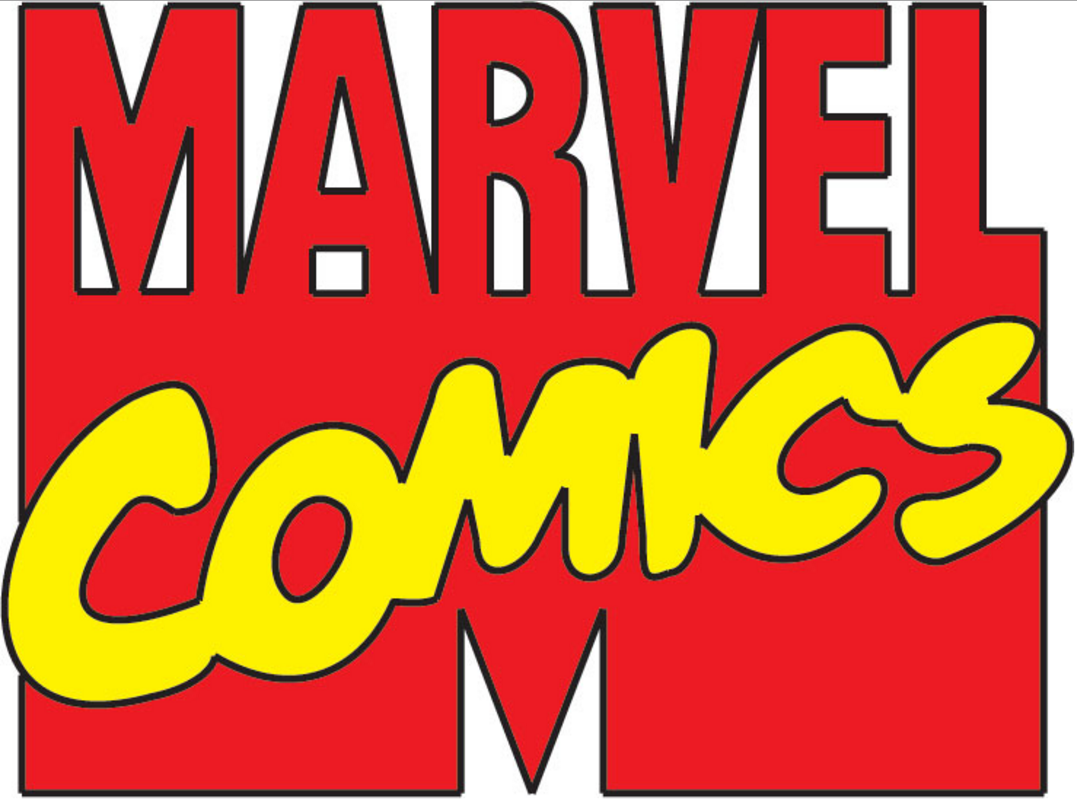

In [3]:
import chart_studio.plotly
import plotly.graph_objs as go
from chart_studio.plotly import plot, iplot
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import networkx as nx
%matplotlib inline 
from IPython.display import display
from PIL import Image


path=('../input/marvel/MArvel commics.png')
display(Image.open(path))

## We all know Marvel Universe and all the super Heros, but "What if they exist", and what "if They have their own interaction"...Sadly that will not happen .... But We can Speculate and Think about so many situations .. for example ***Who is the most Popular among them*** , ***Who do they Talk for a favor***, Who is the one ***that has help other the most***`, Here is where social network analysis comes in.. In this notebook you will find the answer of all these funny questions....

In [4]:
e = pd.read_csv('../input/the-marvel-universe-social-network/edges.csv') # Edges
h = pd.read_csv('../input/the-marvel-universe-social-network/hero-network.csv') # Hero
n = pd.read_csv('../input/the-marvel-universe-social-network/nodes.csv') # Nodes

## Dont worry about the Numbers.. you have to follow...
Right here we have more than 57 thousand interactions , in other words when a super heroe find, help, fight, talk, etc to other superheroe.. this is our start point 
How does it Work? Well It is simple 
* Tony Stark: Did you know?
* Steve Rogers: I didn't know it was him.
* Tony Stark: Don't bullshit me, Rogers! Did you know?
* Steve Rogers:Yes.
* Tony : He killed My mom 
* Roger : Dont kill him **I LOVE HIM ** jajajaj 

When Tony talks to Steve  = Tony --->Roger
when Roger Talks to Tony  =  Roger ---> Tony

There We have an interaction Tony <---> Roger
These concepts are so simple that and youtube video can explain it better than me ... 
So The next section show more than 57 K interaction that happened in the comic books

In [5]:
h.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574467 entries, 0 to 574466
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   hero1   574467 non-null  object
 1   hero2   574467 non-null  object
dtypes: object(2)
memory usage: 8.8+ MB


In [6]:
he = nx.from_pandas_edgelist(h, source = "hero1", target = "hero2")
nx.info(he)

'Name: \nType: Graph\nNumber of nodes: 6426\nNumber of edges: 167219\nAverage degree:  52.0445'

* # Degree Centrality 

> ## To have a better Comprenhension about the findings We have to talk about Degree Centrality "**What the Hulk is that**"
let me give you an examplem

* Let asume that you are in a party " they are always full of people" you might notice people tend to make small groups all arround the place, so which group is biggest and overall which group is the one in the center of everything (in the center of the group and the center of the party)

* Same concept here , think of This super heroes " how many times do they appeared in others comics and out of all those comics that have been published who was the one who appeared the most.

When you find that specific Hero you will have found the Degree centrality or in other words the guy that has been in all the comics... in our case **the top 5** :
 
1.  Spiderman
2.  Iron Man
3. Beast
4. Hulk
5. Cyclops

In [7]:
#Degree Centrality 
MF = nx.degree_centrality(he)

counter = 0
for w in sorted(MF, key = MF.get , reverse = True):
    counter = counter + 1
    if counter == 10:
        break
    print(w,'{:0.2f}'.format(MF[w]))

CAPTAIN AMERICA 0.30
SPIDER-MAN/PETER PAR 0.27
IRON MAN/TONY STARK  0.24
THING/BENJAMIN J. GR 0.22
MR. FANTASTIC/REED R 0.21
WOLVERINE/LOGAN  0.21
HUMAN TORCH/JOHNNY S 0.21
SCARLET WITCH/WANDA  0.21
THOR/DR. DONALD BLAK 0.20


* # EigenVector 

> ## This is easier to understand " This is about Which superheroe knows more superheroes"

* Who knows more super heroes .. DeadPool or Doctor Xavier? ... well obviously Doctor X Because He knows all the student and all the people in the word...... and many more justification.. 

* Think of this as " How many superheroes appeared in the super Heroes X " for example We have a commic "Spider Man #3" so How many superheroes apperead in this comic book and their role, did they fight , did they help , or ask for something"

**the top 5** of knowing more superheroes for (appeared, help, fight along , etc) are:
 
1.  The beast
2.  Angel 
3. Iron Man
4. Scarlet Witch
5. Captain America

In [8]:
#EigenVector
EV = nx.eigenvector_centrality(he)
counter = 0
for w in sorted(EV, key =EV.get,  reverse = True):
    counter = counter + 1
    if counter == 10:
        break
    print(w,"{:0.4f}".format(EV[w]))

CAPTAIN AMERICA 0.1168
IRON MAN/TONY STARK  0.1025
SCARLET WITCH/WANDA  0.1008
THING/BENJAMIN J. GR 0.1008
SPIDER-MAN/PETER PAR 0.1002
MR. FANTASTIC/REED R 0.0997
VISION  0.0985
HUMAN TORCH/JOHNNY S 0.0985
WOLVERINE/LOGAN  0.0984


* # Betweeness_Centrality

> ## This is **The Most important** .. who said that... well..  "Mohammed Zuhair" the guys who knoe everything about networks

* This is the guy who know everyone and the one who can get what you need. let me make a asumption and a question:


* Deadpool wanta to know Iron Man .. Which super hero will he need to talk to ? ... Doctor X, Wolvering, Storm?... Well the answer "Doctor Strange" Because they were togeher in Doctor strange comic #4 .. Deadpool talks to Dr. strange and Dr. Strange to Tony and << Bam , Boom>>.. Done Dotor Strange is the Man 

* But in Our case We have to consider so many super heroes and find the one who can talk to most of them .....Yeah you might get surprised 


*the top 5** friend that any super heroe should have arer (appeared, help, fight along , etc) are:
 
1.  Spider Man
2.  Hulk 
3. Cyclop
4. Iceman
5. Iron Man

In [9]:
#Betweeness_Centrality
BC = nx.betweenness_centrality(he)
counter = 0
for w in sorted(BC, key =BC.get,  reverse = True):
    counter = counter + 1
    if counter == 10:
        break
    print(w,"{:0.4f}".format(BC[w]))


SPIDER-MAN/PETER PAR 0.0735
CAPTAIN AMERICA 0.0570
IRON MAN/TONY STARK  0.0372
WOLVERINE/LOGAN  0.0357
HAVOK/ALEX SUMMERS  0.0357
DR. STRANGE/STEPHEN  0.0292
THING/BENJAMIN J. GR 0.0254
HAWK 0.0248
HULK/DR. ROBERT BRUC 0.0239


* # Network

> ## Here We have the network representation... is not perfect yet.. Im goona keep working on that ...
* The points in the center it is the Central degree "the guy that has been in all the comics"
* The betweeness Centrality is hard to Find but I hope you enjoy the 3D Graph 
* There are more info that we can get from this data set so go a head and please vote this up and post so comments 

In [10]:
#h= h.iloc[np.r_[100:350, 500:800,1230:1900,2500:5600]]
h= h.iloc[:10000,:2]
he = nx.from_pandas_edgelist(h, source = "hero1", target = "hero2")
print(nx.info(he))

Name: 
Type: Graph
Number of nodes: 674
Number of edges: 6255
Average degree:  18.5608


In [11]:
import igraph as ig

#Numbers of Nodes
N = he.number_of_nodes()

#List of Edge
L = he.number_of_edges()

#Graph objects
Edges_name = [e for e in he.edges()] #Edges Names

Edges= nx.convert_node_labels_to_integers(he) #Mapping all Nodes into Numbers
Edges = [e for e in Edges.edges()]

#Graph
G = ig.Graph(Edges, directed = False)

# Geolocalization
layt = G.layout('kk',dim = 3)  #3D Localization

#Given X,y,z Position
Xn=[layt[k][0] for k in range(N)]# x-coordinates of nodes
Yn=[layt[k][1] for k in range(N)]# y-coordinates
Zn=[layt[k][2] for k in range(N)]# z-coordinates

Xe=[]
Ye=[]
Ze=[]

#Grouping Coordinates
for e in Edges:
    Xe+=[layt[e[0]][0],layt[e[1]][0], None]# x-coordinates of edge ends
    Ye+=[layt[e[0]][1],layt[e[1]][1], None]
    Ze+=[layt[e[0]][2],layt[e[1]][2], None]
    
#Nodes Name 
labels = []
group = []

for i in range(len(Edges_name)):
    value = Edges_name[i][0]
    labels.append(value)
    
for i in range(len(Edges)):
    value = Edges[i][0]
    group.append(value)
    
group =[]
group.extend(np.repeat(1,2000))
group.extend(np.repeat(2,2000))
group.extend(np.repeat(3,3000))
group.extend(np.repeat(4,1000))
group.extend(np.repeat(5,2000))

trace1=go.Scatter3d(x=Xe,y=Ye,z=Ze,mode='lines',
                    line=dict(color='rgb(125,125,125)', width=1),hoverinfo='none')

trace2=go.Scatter3d(x=Xn,y=Yn,z=Zn,mode='markers',name='SuperHeroe',
                    marker=dict(symbol='circle',size=4,color=group,colorscale='Viridis',line=dict(color='rgb(50,50,50)', width=0.5)),
                    text=labels,hoverinfo='text')

axis=dict(showbackground=False,showline=False,zeroline=False,
          showgrid=False,showticklabels=False,title='')

In [12]:
layout = go.Layout(
         title="Network Of appaerance of Marvel<br> SuperHeroes (3D visualization)",
    autosize=True,
         width=1000,
         height=1000,
         showlegend=False,
         scene=dict(
             xaxis=dict(axis),
             yaxis=dict(axis),
             zaxis=dict(axis),
        ),
     margin=dict(
        t=100
    ),
    hovermode='closest',
    annotations=[
           dict(
           showarrow=False,
            text="Done by Msc. Marvin Garcia",
            xref='paper',
            yref='paper',
            x=0,
            y=0.1,
            xanchor='left',
            yanchor='bottom',
            font=dict(
            size=14
            )
            )
        ],    )

data=[trace1, trace2]
fig=go.Figure(data=data, layout=layout)
fig.show()